
# Sparse Column Selection with OMP 






## Applications
- **Feature / variable selection (interpretable regression):** Pick a small subset of columns (features) that explain the target variable well.
- **Sensor/actuator placement:** Choose a few sensor locations (columns of a physics/design matrix) to approximate observed fields.
- **Portfolio construction (toy):** Represent a return vector as a sparse mix of a few assets (columns).
- **Column Subset Selection Problem (CSSP):** Find representative columns of a data matrix to approximate other columns.


# Sparse Approximation with Orthogonal Matching Pursuit (OMP)

You are given a matrix `A` (shape m x n) and a target vector `b` (shape m,).
The goal is to find a **sparse vector x** such that `A @ x` is close to `b`.

You will implement the Orthogonal Matching Pursuit (OMP) algorithm to approximate `b`
using only a few columns of `A`.

---

## Your Tasks

1. Implement a function `omp(A, b, s)` that finds an approximate solution to:

       minimize ||b - A @ x||_2
       subject to x having at most s non-zero entries.

   In other words, pick up to `s` columns of `A` that best reconstruct `b`.

2. Experiment with different sparsity budgets `s` (for example 1, 2, 4, 8)
   and report the reconstruction error `np.linalg.norm(b - A @ x_hat)`.

3. Add small Gaussian noise to `b` and see how OMP behaves
   compared to using all columns of `A` in a least squares fit.

4.  Try multiple target vectors `b` (for example, take them directly
   as columns of `A` with added noise) and see if OMP recovers the correct columns.

---

## Notes / Hints

- Start with a random or synthetic dataset.
- Initialize your residual `r = b.copy()`.
- At each iteration:
  - Find the column of `A` most correlated with the residual.
  - Add it to the active set of columns.
  - Solve a least squares problem on the active set to update `x`.
  - Update the residual.
- Stop when you reach the sparsity limit `s` or the residual is very small.



In [1]:

# === Setup ===
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Problem size
m, n = 60, 120     # A is m x n
A = np.random.randn(m, n)
# Normalize columns (often helpful for greedy selection)
A = A / np.linalg.norm(A, axis=0, keepdims=True)

# Create a synthetic sparse ground-truth x*
true_support = np.array([3, 17, 51])   # you can change this
x_star = np.zeros(n)
x_star[true_support] = np.array([1.2, -0.7, 0.9])

# Generate Gaussian noise: one value per row of A
sigma = 0.02  # noise std (set to 0.0 to remove noise)
noise = sigma * np.random.randn(m)
b = A @ x_star + noise      # Construct the target from the true sparse coefficients plus noise

print(f"A shape: {A.shape}, sparsity of x*: {(x_star!=0).sum()}")
print(f"Noise level sigma: {sigma}")


A shape: (60, 120), sparsity of x*: 3
Noise level sigma: 0.02



## Implement OMP
Fill in the `omp` function below. Hints:
- Start with residual `r = b` and empty support set `S`.
- At each iteration:
  1. Pick the column index `j` that maximizes `|A[:, j]^T r|`.
  2. Add `j` to the support set `S`.
  3. Solve least squares on the active set: `A_S c ≈ b` to update coefficients on `S`.
  4. Update residual `r = b - A_S c`.
- Stop when you reach the sparsity budget `s` or the residual is tiny.


In [2]:

def omp(A, b, s, tol=1e-8):
    """
    Implement Orthogonal Matching Pursuit (OMP).
    Args:
        A: (m, n) matrix
        b: (m,) vector
        s: int, sparsity (max number of nonzeros in x)
        tol: float, stopping tolerance on residual norm (optional)
    Returns:
        x_hat: (n,) estimated sparse vector
        support: list of selected column indices (in selection order)
        residuals: list of residual norms per iteration
    """
    # Start with zero coefficients and no selected columns
    x_hat = np.zeros(A.shape[1])
    support = []
    residuals = []
    r = b.copy()

    for _ in range(min(s, A.shape[1])):
        # Stop if the remaining error is already small
        if np.linalg.norm(r) <= tol:
            break

        corr= np.abs(A.T @ r)       # Measure how strongly each column matches the residual
        # Prevent selecting a column that is already in the support
        corr[support] = -np.inf
        j = int(np.argmax(corr))    # Select the column with the largest absolute correlation
        support.append(j)

        # Refit coefficients using ALL selected columns
        A_S = A[0:, support]
        coefficients, *_ = np.linalg.lstsq(A_S, b, rcond=None)

        # Update the sparse solution
        x_hat[support] = coefficients

        # Update the unexplained part of b and record its size
        r = b - A_S @ coefficients
        residuals.append(np.linalg.norm(r))

    return x_hat, support, residuals



## Run Experiments
Vary the sparsity budget `s` and measure the reconstruction error.


In [3]:

def run_experiment(A, b, sparsities=(1, 2, 3, 4, 6, 8)):
    results = []
    for s in sparsities:
        x_hat, support, residuals = omp(A, b, s)
        err = np.linalg.norm(b - A @ x_hat)
        results.append((s, err, support, residuals))
    return results

results = run_experiment(A, b)

for s, err, support, residuals in results:
    print(f"s={s:2d} | ||b - A x_hat||_2 = {err:.4e} | support={support}")


s= 1 | ||b - A x_hat||_2 = 1.2513e+00 | support=[3]
s= 2 | ||b - A x_hat||_2 = 6.9137e-01 | support=[3, 51]
s= 3 | ||b - A x_hat||_2 = 1.6750e-01 | support=[3, 51, 17]
s= 4 | ||b - A x_hat||_2 = 1.5439e-01 | support=[3, 51, 17, 114]
s= 6 | ||b - A x_hat||_2 = 1.3758e-01 | support=[3, 51, 17, 114, 63, 10]
s= 8 | ||b - A x_hat||_2 = 1.2628e-01 | support=[3, 51, 17, 114, 63, 10, 16, 11]


- The reconstruction error decreases as the sparsity budget increases. At s = 3, OMP recovers all three true column indices, although in a different order. The remaining error comes from noise that the selected columns cannot explain. Increasing s beyond 3 reduces the residual further by selecting extra columns that fit some of the noise.


## Plot Residual Norm vs. Iterations


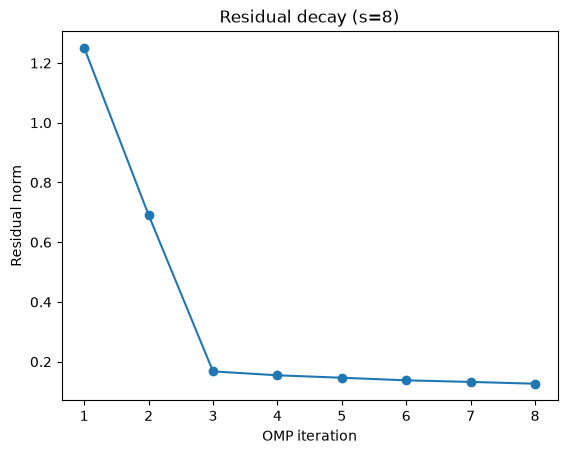

In [4]:

# Pick the run with largest s to show residual decay
s, err, support, residuals = results[-1]
plt.figure()
plt.plot(np.arange(1, len(residuals)+1), residuals, marker='o')
plt.xlabel('OMP iteration')
plt.ylabel('Residual norm')
plt.title(f'Residual decay (s={s})')
plt.show()



##  Compare to Full Least Squares
How does OMP with a small `s` compare to using **all** columns (ordinary least squares)?


In [5]:

# Full least squares using all columns (if m >= n, use lstsq; if m < n, minimum-norm solution)
# We have already added noise to b
#x_ls is the least square solution and ls_err is the error
x_ls, *_ = np.linalg.lstsq(A, b, rcond=None)    # Fit b using all columns of A
ls_err = np.linalg.norm(b - A @ x_ls)   # Calculate the reconstruction error

print(f"Full least-squares error: {ls_err:.4e}")


Full least-squares error: 3.6561e-15



## Multiple Targets
Try using several targets \(b\) (e.g., noisy copies of different **columns of A**) and see whether OMP recovers the correct column indices in the support.


In [6]:

# Example: draw k random columns from A, mix them, add noise, and test recovery
def make_target_from_columns(A, cols, coeffs, sigma=0.02):
    x = np.zeros(A.shape[1])
    x[cols] = coeffs

    # Generate fresh noise and construct this target
    noise = sigma * np.random.randn(A.shape[0])
    b = A @ x + noise
    
    return b, x

cols = [5, 9, 33]
coeffs = [1.0, -0.8, 0.5]
b2, x2_true = make_target_from_columns(A, cols, coeffs, sigma=0.02)

x2_hat, supp2, res2 = omp(A, b2, s=3)
print("True support:", np.where(x2_true!=0)[0].tolist())
print("Recovered support:", supp2)
print("Error ||b - A x_hat||_2 =", np.linalg.norm(b2 - A @ x2_hat))


True support: [5, 9, 33]
Recovered support: [5, 9, 33]
Error ||b - A x_hat||_2 = 0.16592169838024426


In [7]:
# OVO NIJE POTREBNO ALI MOŽE BITI TU ZA NEKU PROVJERU
for cols in ([5], [9], [5, 9, 33]):
    coeffs = [1.0] * len(cols)
    b_test, _ = make_target_from_columns(A, cols, coeffs)

    x_test, recovered, _ = omp(A, b_test, s=len(cols))

    print(
        f"True: {cols} | Recovered: {recovered} | "
        f"Correct: {set(cols) == set(recovered)}"
    )

True: [5] | Recovered: [5] | Correct: True
True: [9] | Recovered: [9] | Correct: True
True: [5, 9, 33] | Recovered: [33, 5, 9] | Correct: True



## What to Hand In
- Your completed `omp` implementation (this notebook).
- A short note (5–8 sentences) summarizing:
  - How the error behaves as `s` increases.
  - Whether OMP recovers the true support when `b` is made from a few columns of `A`.
  - Any effect of noise you observed.


## CONCLUSION

As the sparsity budget s increases, the reconstruction error decreases. The error drops sharply from approximately 1.2513 at s = 1 to 0.1675 at s = 3, with smaller improvements afterward. At s = 3, OMP correctly recovers the original support [3, 17, 51], although in a different order. OMP also correctly recovers the support [5, 9, 33] for another noisy target, with a reconstruction error of approximately 0.1659. All additional single-column and three-column tests recover the correct support, showing that selection order does not affect support recovery. With Gaussian noise at sigma = 0.02, a nonzero residual remains even when the correct support is recovered. Increasing s beyond the true sparsity selects extra columns that fit some of the noise. Full least squares achieves an almost zero residual of approximately 3.66e-15, but fitting the noisy target exactly does not guarantee recovery of the original sparse coefficients.